# Notebook 02 — Recording demonstrations

In notebook 01 we built a world full of random navigation episodes. Now we record **demonstrations**: drives to
the goal, where the computer stores what the camera saw and which command was given. They are the training data for
the model in notebook 04 (*imitation learning*: the model learns to copy them).

**What you will learn here**
1. What *imitation learning* (behaviour cloning) is, and why the quality of the demonstrations
   decides almost everything about the final model.
2. Two classic problems of imitation learning, **multimodality** and **compounding errors**, and how
   our design deals with them.
3. The **LeRobot dataset format**: how robot data is stored as frames, episodes, videos and task strings.
4. How to pair each camera image with the right action (an easy place for silent bugs).
5. How to check a dataset with plots *before* spending hours of GPU time training on it.

**The plan**
1. Test the whole recording pipeline with the scripted expert from notebook 01 (no driving needed).
2. **Drive a few episodes yourself** (sections 7–9). This is hands-on: you see how a demonstration is made and
   what makes it good or bad. These drives are *not* needed for training.
3. **Record the training data with a scripted driver** (section 10): 300 drives in about 10 minutes. Recording
   that many by hand takes many hours, and the scripted driver is designed so that everything it does can be
   explained from the camera picture.

## 1. Setup

Same as before, plus a small helper `run_script` that starts one of our scripts in its own process
and prints its output **live** in this notebook. (The simulator windows need their own process,
because Genesis can only build one scene per process and the Jupyter kernel must stay responsive.)
Noise from the video encoder is filtered out.

In [1]:
import sys, re, json, shutil, subprocess
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
RUNS = PROJECT_ROOT / "runs"; RUNS.mkdir(exist_ok=True)
DATASETS = RUNS / "datasets"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

NOISE = re.compile(r"Svt\[|\[mp4 @|Map:|QFontDatabase|Qt no longer ships|\[Genesis\]|^\s*$")

def run_script(*args):
    # Run a project script with the notebook's Python, streaming its useful output here.
    cmd = [sys.executable, "-u", *map(str, args)]
    p = subprocess.Popen(cmd, cwd=PROJECT_ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    tail = []
    for line in p.stdout:
        tail = (tail + [line])[-40:]
        if not NOISE.search(line):
            print(line, end="", flush=True)
    p.wait()
    if p.returncode != 0:
        print(f"\n*** exited with code {p.returncode}. Last output:\n" + "".join(tail))
    return p.returncode

def already_have(ds_dir, target):
    """True if the dataset already holds `target` kept drives (re-running the notebook won't re-open the recorder)."""
    info = ds_dir / "meta" / "info.json"
    n = json.load(open(info))["total_episodes"] if info.exists() else 0
    if n >= target:
        print(f"{ds_dir.name} already has {n} kept drives (target {target}): skipping recording. Raise TARGET to record more.")
    return n >= target

import lerobot
from carsim.device import describe
print("lerobot", lerobot.__version__, "|", describe())

lerobot 0.7.0 | device = cuda: NVIDIA GeForce RTX 4080 SUPER, 15.6 GB | PyTorch 2.15.0+cu134 | Linux 7.2.14-arch1-1


## 2. Imitation learning in one picture

The simplest way to teach a robot is to **show** it. We record pairs of

> *what the robot saw* → *what the expert did*

and train a neural network to predict the action from the observation. This is ordinary
**supervised learning**, the same idea as an image classifier. The "labels" are your steering
commands instead of class names. It is called **behaviour cloning (BC)** or **imitation learning (IL)**.

```
 recording (this notebook)                   training (notebook 04)
 ─────────────────────────                   ───────────────────────
 camera image ─┐                              camera image ─┐
 prompt text  ─┼─► YOU ─► action (vx,vy,wz)   prompt text  ─┼─► NETWORK ─► predicted action
 car speed    ─┘             │                car speed    ─┘                    │
                             └──── stored as the "label" ─────── loss = how far ─┘
                                                                 from your action
```

The network can only become as good as the examples. It copies everything: good habits, bad
habits, hesitations and inconsistencies. That is why this notebook is about **data quality**, not
just data collection.

### Two classic problems you should know about

**1. Multimodality: "there is more than one right answer".**
An obstacle sits straight ahead. Sometimes you pass it on the left, sometimes on the right. Both are
fine. But a naive network trained with a mean-squared-error loss predicts the **average** of
"left" and "right", which is "straight ahead": into the obstacle!

```
     the demos:    ↖ left  (50%)        naive MSE model:   ↑  average = crash
                   ↗ right (50%)
```
This is why smolVLA uses a **flow-matching action head**: it learns the whole *distribution*
of actions ("left OR right") and samples one of them, instead of averaging. Still, demonstrations help by being *consistent* where it costs nothing, e.g. by searching for a hidden goal
the same way every time (our scripted driver in section 10 always searches to the left).

**2. Compounding errors (also called covariate shift).**
The model is never perfect. A small error moves the car to a place that looks slightly different
from anything in your demonstrations. There its prediction is a bit worse, so it drifts further,
and so on:

```
 the demos:    ─────────────────────► goal
 the model:    ──────╲
                      ╲___ "I've never seen this view before" ___ crash
```
The remedies:
- **Demonstrations that include recoveries.** If you sometimes drift off and then correct, the data
  shows the model how to get back. (Don't crash on purpose; just don't throw away an episode only
  because it wasn't perfectly straight.)
- **Variety**: many different layouts, starting angles and distances.
- **Reinforcement learning later** (notebook 05). The model then practises on its own mistakes, which
  is the strongest fix of all, and the main reason this project has an RL phase.

## 3. How the data is stored: the LeRobot dataset format

We use **LeRobotDataset v3**, the format of Hugging Face's LeRobot library. smolVLA was trained on
data in this format, and its training code reads it directly. Its vocabulary:

| term | meaning in our project |
|---|---|
| **frame** | one control step (0.1 s): one camera image + speed + the action you took |
| **episode** | one attempt at one layout, from your first key press to success |
| **task** | the text instruction of the episode, e.g. *"go find the red ball"* |
| **feature** | one named column, e.g. `action` or `observation.images.front` |
| **fps** | frames per second = our control rate, 10 |

On disk a dataset is a folder:
```
runs/datasets/human_demos/
├── meta/
│   ├── info.json          what features exist, their shapes and types, fps, counts
│   ├── tasks.parquet      the list of distinct prompts
│   ├── stats.json         mean / std / min / max of every feature (used to normalise inputs)
│   └── episodes/...       one row per episode: length, task, where its data and video live
├── data/chunk-000/file-000.parquet               all numeric columns, one row per frame
└── videos/observation.images.front/chunk-000/file-000.mp4    the camera frames, as video
```
**Why store the images as video?** One 256×256 RGB frame is 196 KB raw. Video compression uses the
fact that consecutive frames are almost identical and shrinks this ~100-fold, to about 1.5 KB per
frame here. The price: the decoded image differs slightly from the original. We measured the
difference at about 1.2 out of 255 per pixel, invisible to the eye and harmless for training.

**Parquet** is a column-oriented table file (like a compressed spreadsheet). You can open it with pandas.

### 3.1 Our features

Here is the exact list of columns we record (defined in `carsim/recording.py`):

In [2]:
from carsim.recording import FEATURES
for k, f in FEATURES.items():
    print(f"{k:28s} {f['dtype']:8s} shape {str(f['shape']):14s} {f['names']}")

observation.images.front     video    shape (256, 256, 3)  ['height', 'width', 'channels']
observation.state            float32  shape (3,)           ['vx', 'vy', 'wz']
action                       float32  shape (3,)           ['vx', 'vy', 'wz']
sim.pose                     float32  shape (3,)           ['x', 'y', 'yaw']
sim.goal_rel                 float32  shape (3,)           ['bearing', 'distance', 'surface_distance']
sim.geodesic_dist            float32  shape (1,)           ['geodesic_dist']
sim.goal_visible             float32  shape (1,)           ['goal_visible']
sim.collision                float32  shape (1,)           ['collision']
sim.episode_seed             int64    shape (1,)           ['seed']


- **`observation.images.front`** and **`observation.state`** are what the policy may look at:
  the camera, and the car's own measured speed (useful to know "am I already moving?").
- **`action`** is the label: the smoothed (ramped) command that was actually sent to the car.
- **`sim.*` columns are privileged ground truth**: the exact pose, where the goal is relative to the
  car (bearing and distance), whether the goal is in view, and collisions. **The policy never gets
  these as inputs**, since a real robot wouldn't have them. We store them because they are free in
  simulation and very useful:
  - for **analysis** (e.g. "does the model fail mostly when the goal starts hidden?"),
  - for a **quiz** in notebook 04: during training the model is also asked *where* a named object is
    (left, centre, right or not in view). The answer comes from these columns. Having to answer forces the model
    to really link the words to what it sees.
- The **task** string (the prompt) is stored with every frame.

## 4. Pairing images and actions correctly

At every control step the recorder does this, **in this order**:

```
   obs_t  ──(you look at it)──►  action_t  ──(car moves 0.1 s)──►  obs_t+1
     │                              │
     └──────── stored together as frame t ────────┘
```
Frame *t* must hold the image **before** the action, because that is all the driver (and later the
network) knows when choosing it. A classic silent bug is storing the image *after* the step
instead. The model then learns to predict an action from a picture that already shows its result:
during training it is a little bit of cheating that works, and when driving it is useless.

We will **verify** the pairing with a test: our car tracks commands almost perfectly (error about
1e-4 m/s, notebook 00), so the *measured speed* in frame *t+1* should equal the *action* of frame *t*.

## 5. The recording app (`scripts/record.py`)

Each episode passes through three phases:

```
 ┌──────────┐ first drive key ┌───────────┐ success / 60 s  ┌──────────┐  K keep → saved to disk
 │  READY   │ ──────────────► │  DRIVING  │ ──────────────► │  REVIEW  │  D discard
 │ (paused) │                 │ recording │                 │ (paused) │  R retry the same layout
 └──────────┘                 └───────────┘                 └──────────┘
   T = retype the prompt        R / N = drop this attempt
```
Design choices, and why:
- **Recording starts at your first key press**, so the time you spend reading the prompt doesn't
  become hundreds of "stand still" frames. Otherwise the model would learn that standing still is
  the most common correct action.
- **Frames are kept in memory until you decide.** Nothing half-finished ever touches the dataset;
  discarding is free.
- **Only successful episodes can be kept.** A timed-out episode teaches "drive around without
  finding it".
- **Episodes with collisions are flagged** in REVIEW; we recommend pressing D for them. It's your call
  per episode, and every collision is recorded in the `sim.collision` column anyway.
- **Each kept episode is written immediately**, so a crash loses at most the current episode. Running
  the app again **appends** to the same dataset, so you can record in several short sessions.
- **Every attempt** (kept or not) is logged in `runs/datasets/<name>_attempts.jsonl`. This tells us
  later how often you had to retry, which layouts were hard, and so on.
- The prompt window (**T**) warns you if your prompt doesn't mention the goal's colour, because
  "go to the ball" is ambiguous when there are three balls.

## 6. Test the pipeline with the expert first

Before you spend time driving, we check that the whole pipeline works using the scripted expert
from notebook 01: **record → save → reload → decode → plot**. A bug found now costs seconds; a bug
found after training costs hours.

The expert keeps only successful episodes **without collisions**. This throwaway dataset is deleted
and re-made each time you run the cell. It takes about 30 s.

In [3]:
EXPERT_DS = DATASETS / "expert_smoke"
shutil.rmtree(EXPERT_DS, ignore_errors=True)
(DATASETS / "expert_smoke_attempts.jsonl").unlink(missing_ok=True)
run_script("scripts/record.py", "--expert", "--episodes", 10, "--seed", 0, "--dataset", EXPERT_DS)

Building scene (the first run compiles GPU kernels, this can take ~1 minute)...


Dataset /home/mayur/Projects/obstacle_avoidance/runs/datasets/expert_smoke: 0 episodes / 0 frames so far


[  1] seed 1826701614  success    5.9s  collisions  0  KEPT  (1/10)


[  2] seed 1367864806  success   13.8s  collisions 10  dropped  (1/10)


[  3] seed 1097657231  success    4.5s  collisions  0  KEPT  (2/10)


[  4] seed  579362555  success   12.7s  collisions  0  KEPT  (3/10)


... (7 outputs left out)

[ 12] seed 1960127675  success    6.3s  collisions  0  KEPT  (9/10)


[ 13] seed 1081530686  success   15.0s  collisions  0  KEPT  (10/10)


Dataset now has 10 episodes / 788 frames.


0

### 6.1 Load it back

`LeRobotDataset(repo_id, root=...)` opens a dataset. Indexing it, `ds[i]`, returns **one frame**
as a dict of PyTorch tensors. This is exactly what the training loop will see in notebook 04.
Note the conversions LeRobot applies: the image comes back as `float32` in [0, 1] with
channels first (3, H, W), the layout PyTorch vision models expect.

In [4]:
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from carsim.recording import load_table, episode_images, read_log, IMAGE_KEY

ds = LeRobotDataset("local/expert_smoke", root=EXPERT_DS)
print(f"{ds.num_episodes} episodes, {ds.num_frames} frames, fps {ds.fps}")
frame = ds[0]
for k, v in frame.items():
    print(f"  {k:30s}", (f"{tuple(v.shape)} {v.dtype}" if hasattr(v, "shape") else repr(v)))
size = sum(f.stat().st_size for f in EXPERT_DS.rglob("*") if f.is_file())
print(f"size on disk: {size / 1e6:.2f} MB  = {size / ds.num_frames / 1e3:.1f} KB per frame (raw would be 196 KB)")

/home/mayur/Projects/obstacle_avoidance/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


10 episodes, 788 frames, fps 10
  observation.state              (3,) torch.float32
  action                         (3,) torch.float32
  sim.pose                       (3,) torch.float32
  sim.goal_rel                   (3,) torch.float32
  sim.geodesic_dist              () torch.float32
  sim.goal_visible               () torch.float32
  sim.collision                  () torch.float32
  sim.episode_seed               () torch.int64
  timestamp                      () torch.float32
  frame_index                    () torch.int64
  episode_index                  () torch.int64
  index                          () torch.int64
  task_index                     () torch.int64
  observation.images.front       (3, 256, 256) torch.float32
  task                           'find the orange cylinder'
size on disk: 1.07 MB  = 1.4 KB per frame (raw would be 196 KB)


### 6.2 Look at one episode

The film strip below shows what the camera saw, decoded from the stored video, so it is exactly
what the model will be trained on. Below it are the actions over time. Things to check:
- the goal from the prompt appears in the frames and gets bigger towards the end;
- the actions end at zero (the car has to **stop** for success);
- the expert's actions can jump from one step to the next (e.g. the turn rate starts at -1.5 in the
  very first frame), because a controller has no acceleration ramp. Your keyboard commands will
  ramp smoothly instead; we'll compare the two styles at the end of the notebook.

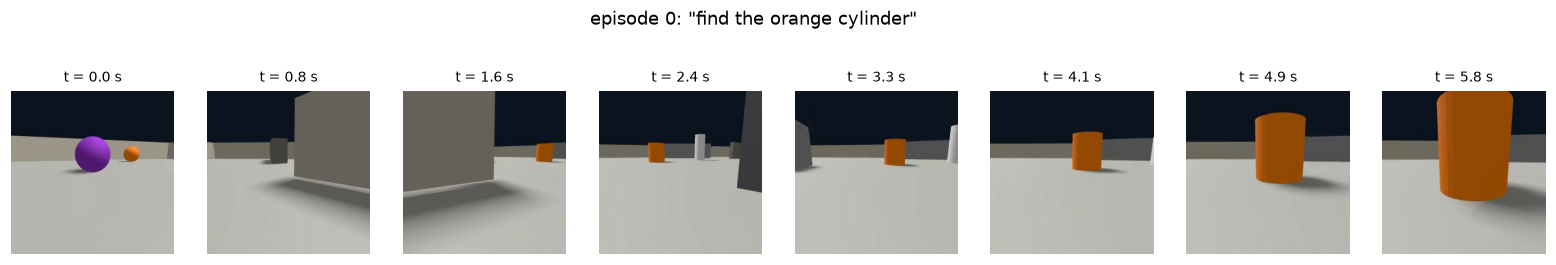

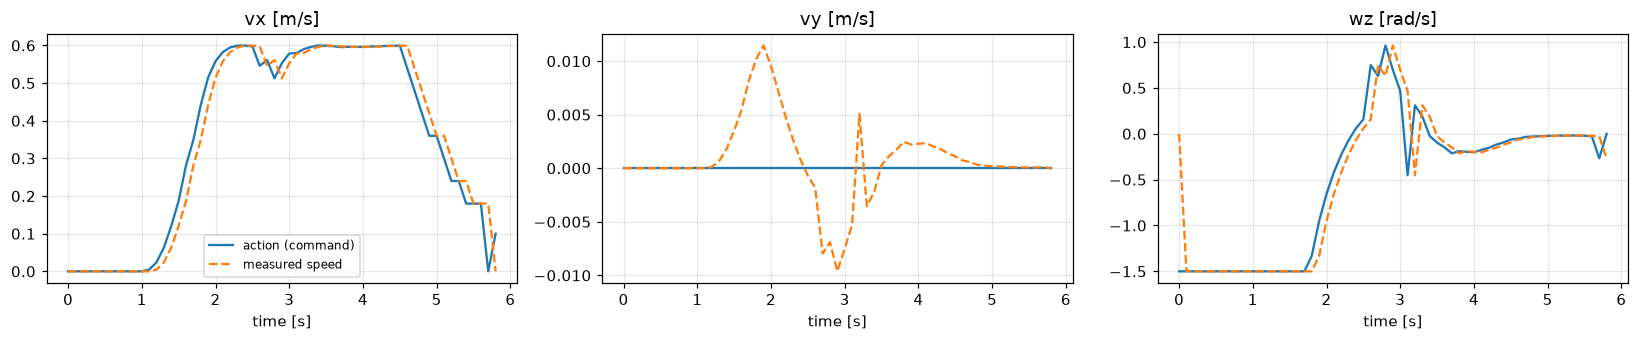

In [5]:
table = load_table(EXPERT_DS)
EP = 0
ep = table[table.episode_index == EP]
imgs = episode_images(ds, EP)
pick = np.linspace(0, len(imgs) - 1, 8).astype(int)
fig, axes = plt.subplots(1, 8, figsize=(18, 2.8))
for ax, i in zip(axes, pick):
    ax.imshow(imgs[i]); ax.set_title(f"t = {i / 10:.1f} s", fontsize=9); ax.axis("off")
fig.suptitle(f'episode {EP}: "{ep.task.iloc[0]}"', y=1.02); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
t = ep.frame_index / 10
for ax, (name, unit) in zip(axes, [("vx", "m/s"), ("vy", "m/s"), ("wz", "rad/s")]):
    ax.plot(t, ep[f"action.{name}"], label="action (command)")
    ax.plot(t, ep[f"observation.state.{name}"], "--", label="measured speed")
    ax.set_title(f"{name} [{unit}]"); ax.set_xlabel("time [s]")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 6.3 The privileged columns tell the story of the episode

`sim.goal_rel.bearing` is the angle to the goal as seen from the car: 0 means straight ahead,
positive means to the left. A good approach turns until the bearing is near 0 and then drives the
distance down. `sim.goal_visible` shows when the goal was actually in the camera's view, which is
blocked when an obstacle is in the way.

(The geodesic distance is undefined for a moment if the car's centre clips an obstacle's safety
margin from notebook 01. The dataset stores 20 m there, and we leave those points out of the plot.)

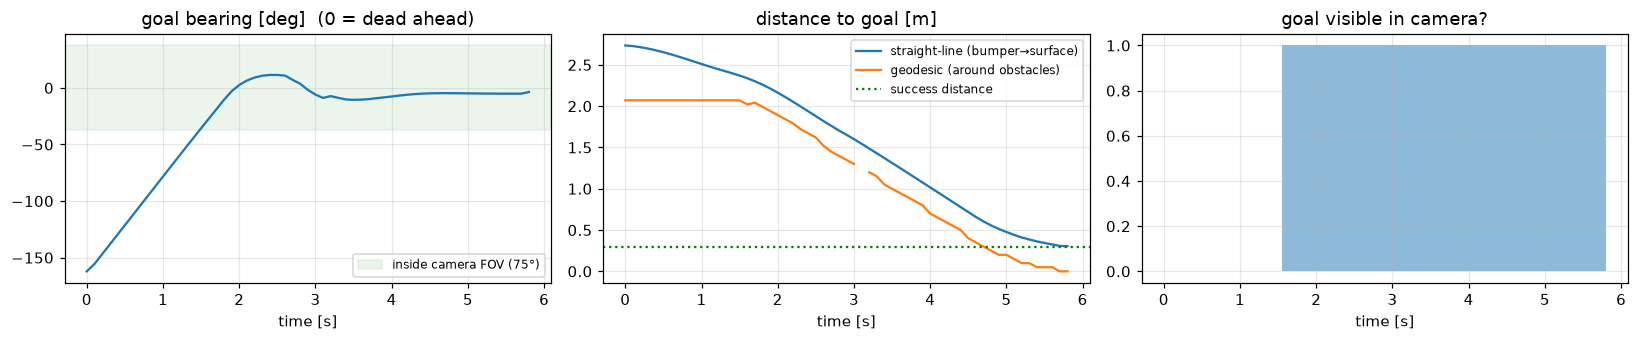

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
axes[0].plot(t, np.degrees(ep["sim.goal_rel.bearing"])); axes[0].set_title("goal bearing [deg]  (0 = dead ahead)")
axes[0].axhspan(-37.5, 37.5, color="g", alpha=0.08, label="inside camera FOV (75°)"); axes[0].legend(fontsize=8)
axes[1].plot(t, ep["sim.goal_rel.surface_distance"], label="straight-line (bumper→surface)")
axes[1].plot(t, ep["sim.geodesic_dist"].where(ep["sim.geodesic_dist"] < 20), label="geodesic (around obstacles)")
axes[1].axhline(0.30, color="g", ls=":", label="success distance"); axes[1].set_title("distance to goal [m]"); axes[1].legend(fontsize=8)
axes[2].fill_between(t, ep["sim.goal_visible"], step="mid", alpha=0.5); axes[2].set_ylim(-0.05, 1.05)
axes[2].set_title("goal visible in camera?"); [a.set_xlabel("time [s]") for a in axes]
plt.tight_layout(); plt.show()

### 6.4 Verify the image ↔ action pairing (section 4)

If frame *t* stores the action taken *after* seeing image *t*, then the measured speed recorded in
frame *t+1* must match the action of frame *t* (the car tracks commands almost perfectly).
We compare the action with the speed at three time offsets. **The error must be clearly smallest
at offset +1.** If it were smallest at offset 0, the image and action would be stored one step
out of sync.

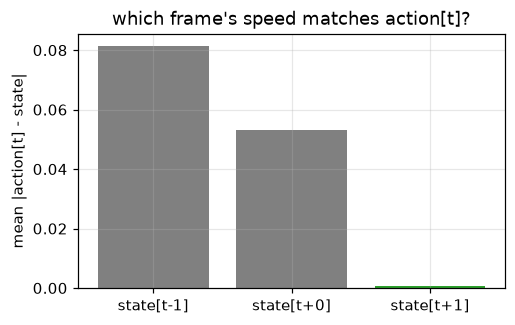

{-1: 0.08139, 0: 0.05326, 1: 0.00085}
Pairing check passed: frame t holds the image BEFORE action t.


In [7]:
def pairing_errors(tab):
    errs = {}
    for lag in (-1, 0, 1):
        e = []
        for _, g in tab.groupby("episode_index"):
            a = g[["action.vx", "action.vy", "action.wz"]].to_numpy()
            s = g[["observation.state.vx", "observation.state.vy", "observation.state.wz"]].to_numpy()
            if lag >= 0:
                e.append(np.abs(a[: len(a) - lag] - s[lag:]).mean())
            else:
                e.append(np.abs(a[-lag:] - s[:lag]).mean())
        errs[lag] = float(np.mean(e))
    return errs

errs = pairing_errors(table)
plt.figure(figsize=(5, 3))
plt.bar([f"state[t{l:+d}]" for l in errs], list(errs.values()), color=["grey", "grey", "tab:green"])
plt.ylabel("mean |action[t] - state|"); plt.title("which frame's speed matches action[t]?"); plt.show()
print({k: round(v, 5) for k, v in errs.items()})
assert errs[1] < 0.1 * min(errs[0], errs[-1]), "pairing looks wrong!"
print("Pairing check passed: frame t holds the image BEFORE action t.")

## 7. How to record good demonstrations

You are now the "expert". Some guidelines, each with the reason behind it:

| guideline | why |
|---|---|
| **Drive smoothly; hold keys rather than tapping them** | Ramped, steady commands are easy to predict from the image. Rapid tapping creates on/off noise the model can't explain. |
| **Never stand still until you reach the goal.** Press the next key *before* releasing the current one, and turn while driving (↑ + ←) | A pause labels a perfectly normal view with "stop". The model then learns that stopping is a fine answer anywhere, and at test time a stopped car sees the same image again and can **freeze**. The author's first 50 demos had 27% pause frames; aim for **under 5%**. The HUD shows a live counter. |
| **When the goal is hidden, search the same way every time**, e.g. rotate on the spot towards the more open side until you see it | Consistent search behaviour is learnable; random searching is close to noise. |
| **Once you see the goal, turn to face it, then drive** | Simple, repeatable structure ("centre the goal in the image, go") is the easiest visual skill to learn. |
| **Stop fully at the goal** (Space works) | The model must learn *when to stop*. Success requires near-zero speed. |
| **Strafe (Q/E) by a consistent rule**: rotate to *find* and roughly face the goal; strafe for *small sideways corrections* while it is in view (centring the goal before the final approach, sliding past an obstacle edge without losing sight of the goal). Combine with ↑ for diagonal motion | Strafing is the mecanum base's special skill, and a model can only learn it from examples. A clear rule ("goal slightly off-centre and visible → strafe; goal far off or hidden → rotate") makes it *learnable*; random use looks like noise. |
| **Don't discard an episode just for a wobble you corrected** | Corrections are valuable *recovery* data (section 2). |
| **Do discard episodes with collisions or long confused wandering** | Those teach bad habits. |
| **Keep the suggested prompt most of the time; rephrase sometimes (T)** | Prompts vary naturally through the templates. Your own phrasings add variety that helps the model understand language rather than memorise templates. Always mention colour and shape. |
| **Short sessions (10–15 min)** | Tired driving becomes sloppy driving. Sessions append to the same dataset. |

### How many demonstrations?
There is no magic number. Some reference points:
- **For this hands-on part, 10 drives are plenty** (about 5 minutes). They are for learning how recording works and
  for comparing your style with the scripted driver's in section 10.
- smolVLA's paper fine-tuned on tasks with ~50 demonstrations each, but those were single manipulation tasks. Our
  task asks for more generalisation: 18 objects × random layouts × language. Training uses **300 scripted drives**
  (section 10), each in a different room. Research on imitation learning finds that the *variety* of scenes matters
  more than repeating the same scene (Lin et al. 2024, *Data Scaling Laws in Imitation Learning*).

## 8. Record your demonstrations

Run the cell below. Two windows open, as in notebook 01: the **3-D "Genesis" window** (click it,
since it needs keyboard focus for driving) and the **FPV** window with the prompt and status.

| key | phase | action |
|---|---|---|
| ↑ ↓ ← → Q E | READY / DRIVING | drive (recording starts at your first key press) |
| Space | DRIVING | stop |
| T | READY | retype the prompt (a small window opens; click the 3-D window again afterwards) |
| K / D | REVIEW | keep / discard the episode |
| R | any | retry the same layout (drops the current attempt) |
| N | any | skip to a new layout (drops the current attempt) |
| Esc | any | save and quit (you can continue later; the dataset is appended to) |

While driving, the FPV window shows your **pause** share (yellow "PAUSED" while you stand still) and
your **strafing** share. In REVIEW, an episode with more than 10% pauses gets a "consider D" hint.

`TARGET` is the total number of kept episodes at which the app stops by itself (10 here). You can quit
earlier with Esc at any time and re-run this cell later to continue where you left off.

In [ ]:
# Your own drives go into runs/datasets/human_demos. They are for learning; training (notebook 04) uses the scripted drives.
HUMAN_DS = DATASETS / "human_demos"
TARGET = 10
if not already_have(HUMAN_DS, TARGET):
    run_script("scripts/record.py", "--dataset", HUMAN_DS, "--target", TARGET)

## 9. Look at what you recorded

These plots are the **data-quality dashboard**. Re-run them after every recording session.
We are looking for:
- **balance**: all 18 goal objects represented, and both visible and hidden starts;
- **efficiency**: how close your paths are to the shortest path (SPL, see notebook 01);
- **consistency**: action distributions without strange spikes;
- **variety of language**: how many distinct prompts.

53 attempts, 50 kept, 50 episodes / 6224 frames in the dataset (10.4 minutes of driving)


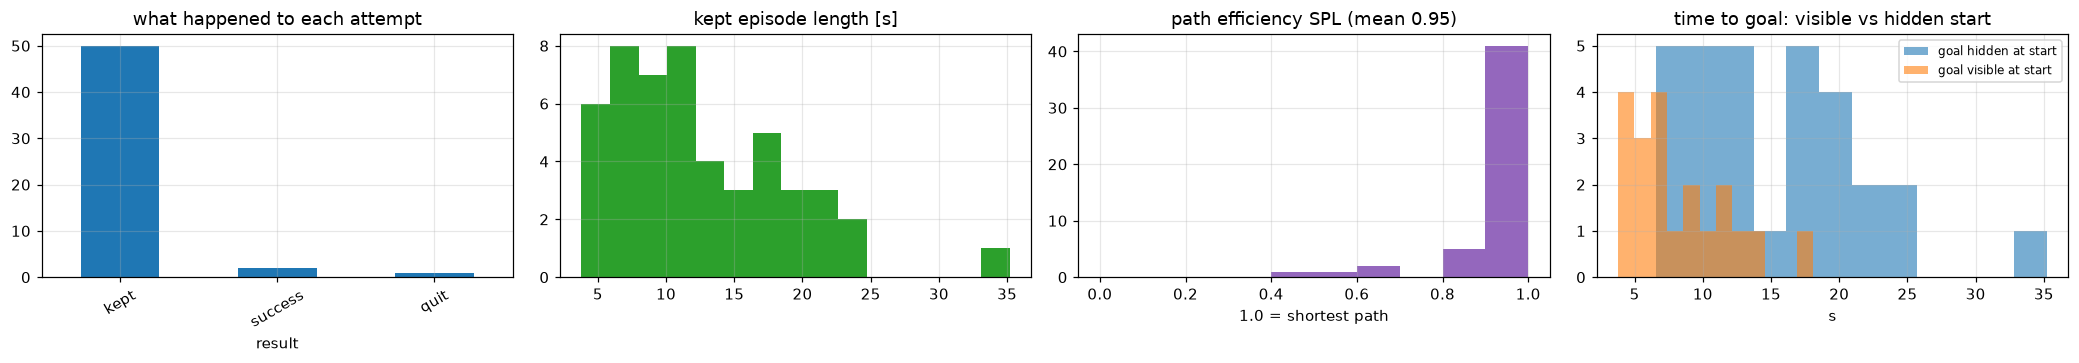

In [8]:
HUMAN_DS = DATASETS / "human_demos"           # your drives (section 8)
attempts = pd.DataFrame(read_log(HUMAN_DS))
if attempts.empty or not (HUMAN_DS / "meta" / "info.json").exists():
    print("No human demonstrations yet - run the recording cell above first.")
else:
    human = load_table(HUMAN_DS)
    kept = attempts[attempts.kept]
    print(f"{len(attempts)} attempts, {len(kept)} kept, {human.episode_index.nunique()} episodes / "
          f"{len(human)} frames in the dataset ({len(human) / 10 / 60:.1f} minutes of driving)")

    fig, axes = plt.subplots(1, 4, figsize=(19, 3.4))
    attempts.assign(result=np.where(attempts.kept, "kept", attempts.outcome)).result.value_counts().plot.bar(ax=axes[0], color="tab:blue")
    axes[0].set_title("what happened to each attempt"); axes[0].tick_params(axis="x", rotation=30)
    axes[1].hist(kept.duration_s, bins=15, color="tab:green"); axes[1].set_title("kept episode length [s]")
    axes[2].hist(kept.spl, bins=np.linspace(0, 1, 11), color="tab:purple")
    axes[2].set_title(f"path efficiency SPL (mean {kept.spl.mean():.2f})"); axes[2].set_xlabel("1.0 = shortest path")
    for vis, g in kept.groupby("start_visible"):
        axes[3].hist(g.duration_s, bins=12, alpha=0.6, label="goal visible at start" if vis else "goal hidden at start")
    axes[3].set_title("time to goal: visible vs hidden start"); axes[3].legend(fontsize=8); axes[3].set_xlabel("s")
    plt.tight_layout(); plt.show()

### 9.1 Coverage: is every goal object represented?

The sampler picks goals uniformly, but with only a handful of episodes many of the 18 objects appear once or never.
A model cannot learn "purple cylinder" if it never saw one as a goal. That's one reason the training data (section 10)
has 300 drives.

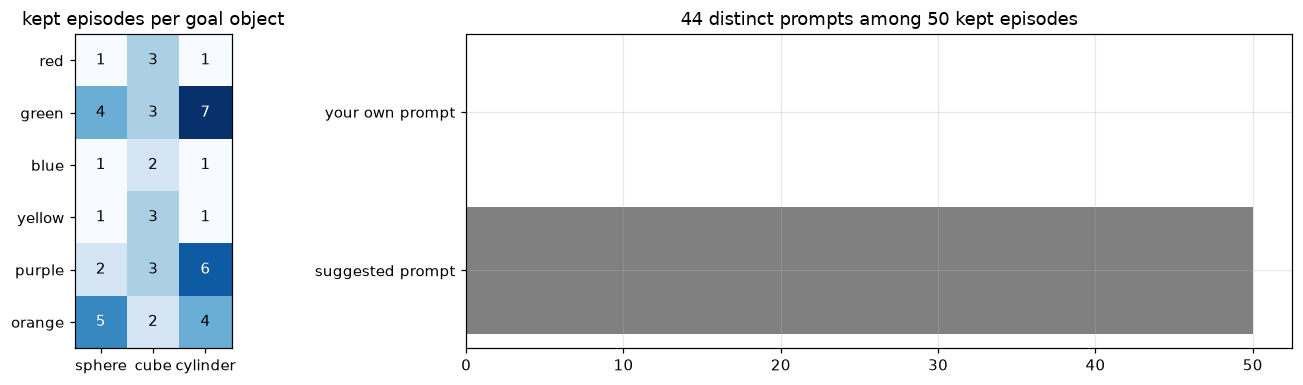

In [9]:
if not attempts.empty and (HUMAN_DS / "meta" / "info.json").exists():
    from carsim.world import SHAPES, COLORS
    counts = kept.goal.value_counts()
    grid = np.array([[counts.get(f"{c} {s}", 0) for s in SHAPES] for c in COLORS])
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
    im = axes[0].imshow(grid, cmap="Blues"); axes[0].grid(False)
    axes[0].set_xticks(range(len(SHAPES)), SHAPES); axes[0].set_yticks(range(len(COLORS)), COLORS)
    for (i, j), v in np.ndenumerate(grid):
        axes[0].text(j, i, v, ha="center", va="center", color="k" if v < grid.max() * 0.6 else "w")
    axes[0].set_title("kept episodes per goal object")
    custom = (kept.prompt != kept.suggested_prompt)
    axes[1].barh(["suggested prompt", "your own prompt"], [(~custom).sum(), custom.sum()], color=["grey", "tab:orange"])
    axes[1].set_title(f"{kept.prompt.nunique()} distinct prompts among {len(kept)} kept episodes")
    plt.tight_layout(); plt.show()
    if custom.any():
        print("Your own prompts:", *sorted(set(kept.prompt[custom])), sep="\n  ")

### 9.2 Your paths on the map

Each episode is rebuilt from its seed (notebook 01), so we can draw your path next to the shortest
one. Look for detours, hesitation loops and the way you searched when the goal started hidden.

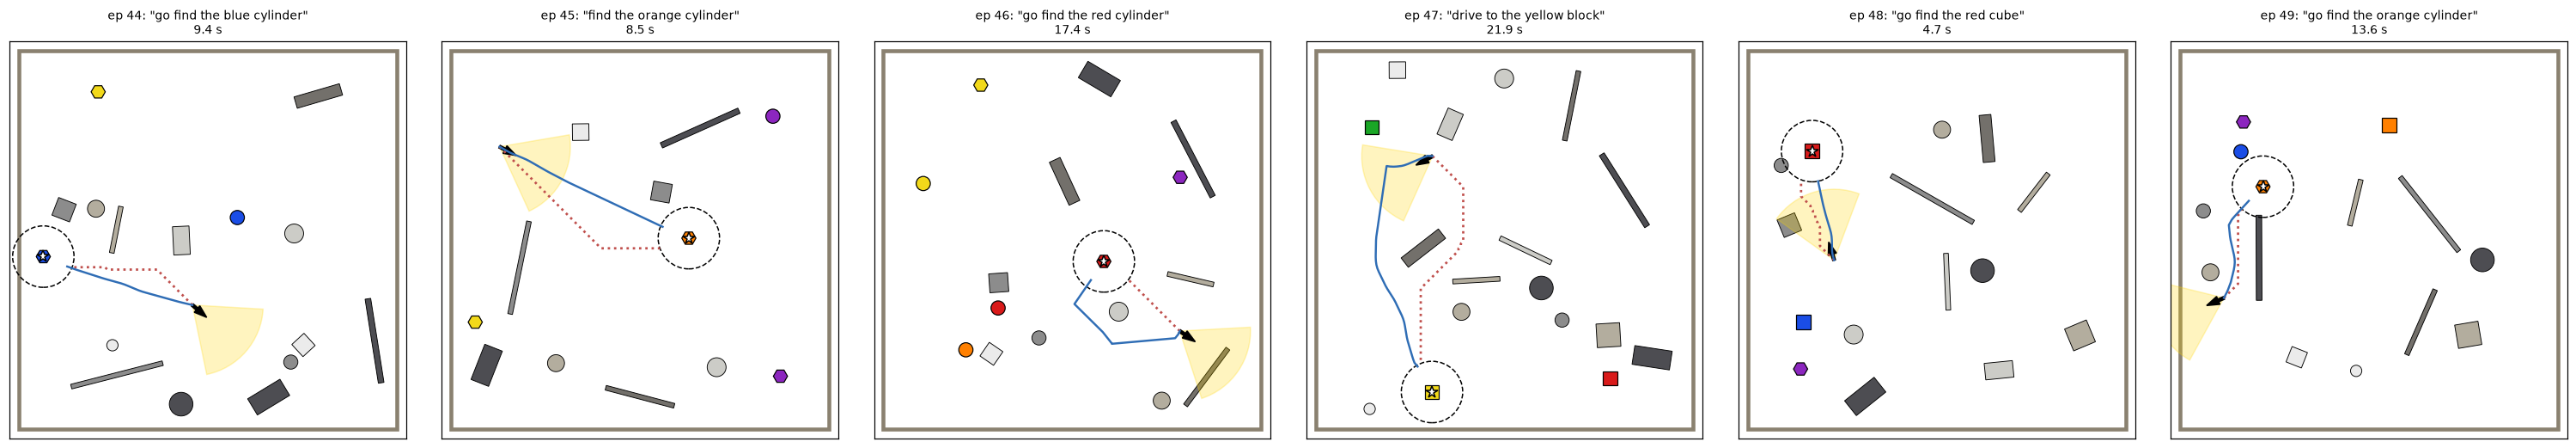

In [10]:
if not attempts.empty and (HUMAN_DS / "meta" / "info.json").exists():
    from carsim.world import sample_episode
    from carsim.viz import draw_episode
    eps = human.episode_index.unique()[-6:]
    fig, axes = plt.subplots(1, len(eps), figsize=(4.6 * len(eps), 4.6), squeeze=False)
    for ax, e in zip(axes[0], eps):
        g = human[human.episode_index == e]
        spec = sample_episode(int(g["sim.episode_seed"].iloc[0]))
        draw_episode(spec, ax=ax, trajectory=g[["sim.pose.x", "sim.pose.y"]].to_numpy(),
                     title=f'ep {e}: "{g.task.iloc[0]}"\n{len(g) / 10:.1f} s')
    plt.tight_layout(); plt.show()

### 9.3 Your driving style vs. the expert's

Histograms of the recorded actions. What to look for:
- **Peaks at the limits** (e.g. wz = ±1.5, vx = 0.8) are frames where a key was held long enough
  to reach full speed. Values in between come from your ramp (and from the expert's
  steering controller).
- **The expert never reverses** except to back off after a bump, and it **never strafes**.
- **The tall bar at 0** for vy (strafing) shows how rarely you strafe. If it is almost all zeros, the
  model will practically never strafe either. That is fine, as long as it is a choice you're happy with.
- A big spike at **all-zero actions** inside episodes would mean a lot of standing still.
- The **per-episode** plots show the share of pause frames (target < 5%) and of strafing frames in each of your
  drives.

We also re-run the **pairing check** from section 6.4 on your data.

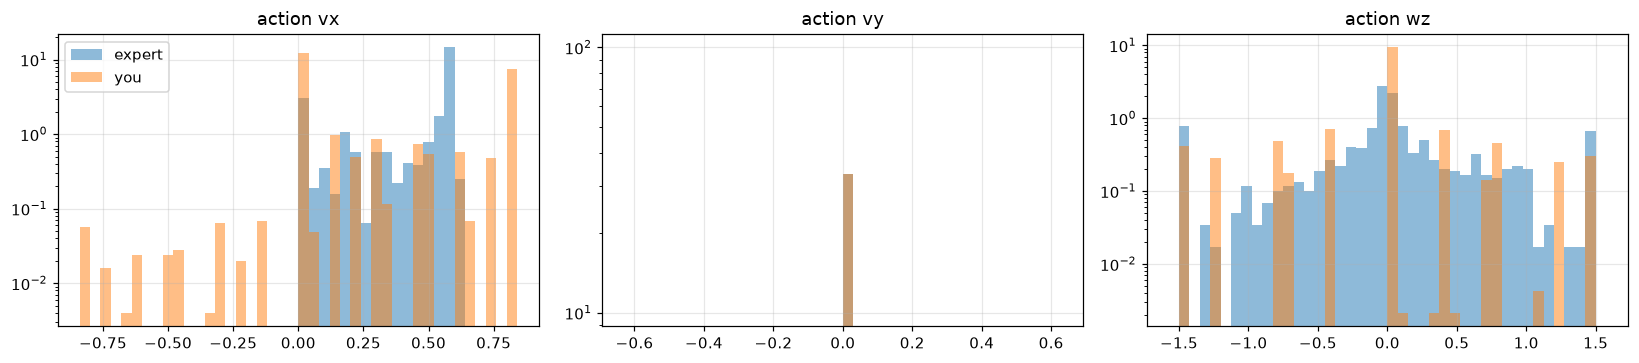

frames with an all-zero action: 27.1%


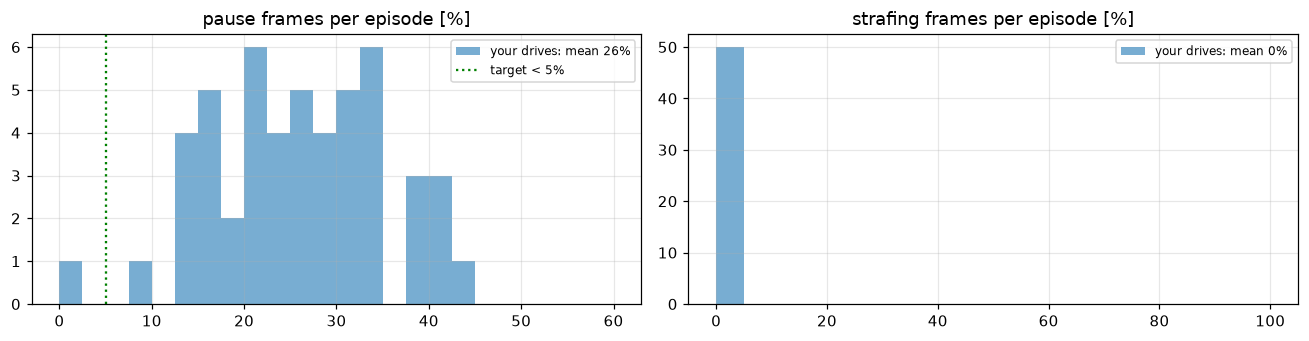

pairing check on your data: {-1: 0.11543, 0: 0.07158, 1: 0.00027} OK


In [11]:
if not attempts.empty and (HUMAN_DS / "meta" / "info.json").exists():
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
    for ax, (name, lim) in zip(axes, [("vx", 0.8), ("vy", 0.6), ("wz", 1.5)]):
        bins = np.linspace(-lim * 1.05, lim * 1.05, 43)
        ax.hist(table[f"action.{name}"], bins=bins, density=True, alpha=0.5, label="expert")
        ax.hist(human[f"action.{name}"], bins=bins, density=True, alpha=0.5, label="you")
        ax.set_title(f"action {name}"); ax.set_yscale("log")
    axes[0].legend(); plt.tight_layout(); plt.show()
    idle = (human[["action.vx", "action.vy", "action.wz"]].abs().max(axis=1) < 1e-3).mean()
    print(f"frames with an all-zero action: {idle:.1%}")
    def style(tab):
        g = tab.groupby("episode_index")
        pause = g.apply(lambda e: (e[["action.vx", "action.vy", "action.wz"]].abs().max(axis=1) < 1e-3).mean(), include_groups=False)
        strafe = g.apply(lambda e: (e["action.vy"].abs() > 0.01).mean(), include_groups=False)
        return pause, strafe
    rounds = {"your drives": human}
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
    for name, tab in rounds.items():
        pause, strafe = style(tab)
        axes[0].hist(pause * 100, bins=np.linspace(0, 60, 25), alpha=0.6, label=f"{name}: mean {pause.mean():.0%}")
        axes[1].hist(strafe * 100, bins=np.linspace(0, 100, 21), alpha=0.6, label=f"{name}: mean {strafe.mean():.0%}")
    axes[0].axvline(5, color="g", ls=":", label="target < 5%")
    axes[0].set_title("pause frames per episode [%]"); axes[1].set_title("strafing frames per episode [%]")
    axes[0].legend(fontsize=8); axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()
    errs_h = pairing_errors(human)
    print("pairing check on your data:", {k: round(v, 5) for k, v in errs_h.items()},
          "OK" if errs_h[1] < 0.1 * min(errs_h[0], errs_h[-1]) else "PROBLEM!")

## 10. The training data: 300 scripted drives

Recording by hand is slow. A **scripted driver** (a small program that drives using the simulator's map) can record
hundreds of drives in minutes, each in a different room. More *different* rooms is exactly what research says matters
most for imitation learning (Lin et al. 2024: variety of scenes beats number of repeats).

**The catch: the scripted driver must only do things the camera can explain.** The plain route-follower from
notebook 01 (`PathFollowingExpert`) turns straight towards a goal hidden behind the car. It knows where the goal is
from the map, but the camera can't see it, so a model trained on it would have to learn "magic". So we use
`SearchThenGoExpert` (`carsim/expert.py`), which behaves like a person:

1. **Goal not in view:** turn on the spot, always to the left, until the goal comes into view, even if another
   object (a decoy) is right in front.
2. **Goal seen:** drive to it along the shortest route.
3. **A full turn without seeing it** (hidden behind an obstacle): head along the route until it appears.

("In view" uses the simulator's exact visibility check, so the driver is never fooled by a lookalike object.)

### 10.1 The finish: drive in like a person

A route-follower naturally brakes early and stops well before the goal. Models trained on such drives copy that and
park just outside the distance the tests count as "reached". So the driver uses a **human speed profile**, measured
from the author's keyboard drives: full speed (0.8) until about 0.5 m from the goal, then about 0.5, then 0.2 for
the last 20 cm, and stop about **12 cm** away (human median: 14 cm). This is `finish="human"` in
`PathFollowingExpert`, and `--finish human` for the recorder.

### 10.2 Record the 300 drives

Six recorders run in parallel, each driving 50 layouts with physics on the CPU (`--cpu`):

| Folders | Scenes | What they teach |
|---|---|---|
| `expert_sgc_rooms_1..3` | ordinary random rooms with obstacles (notebook 01) | general driving, avoiding obstacles, finding hidden goals |
| `expert_sgc_words_1..3` | "words" scenes (`--words --words-mix search`, `carsim/words.py`): two objects side by side (often lookalikes), 1 of 4 objects, or the goal *behind* the car with a decoy in front | reading the instruction: the picture alone doesn't tell which object to drive to |

`--seed-list` makes each recorder drive exactly the layouts in `assets/scripted_layouts/`, the same 300 rooms the
project's results come from. (Each layout is fully defined by one number, its *seed*, see notebook 01.)

Only drives that succeed **without touching anything** are kept; expect about 296 of 300. About **5–10 minutes**
in total. Re-running the cell skips folders that already exist (delete a folder to record it again).

In [12]:
import subprocess, collections
LAYOUTS = PROJECT_ROOT / "assets" / "scripted_layouts"    # the 300 room layouts (seeds) used for the project's results
jobs = []
for kind in ("rooms", "words"):
    for i in (1, 2, 3):
        out = DATASETS / f"expert_sgc_{kind}_{i}"         # expert, Search-then-Go, Close finish
        if out.exists():
            print(out.name, "exists - skipped"); continue
        cmd = [sys.executable, "scripts/record.py", "--expert", "--cpu", "--search-go", "--finish", "human",
               "--dataset", str(out), "--episodes", "0", "--seed-list", str(LAYOUTS / f"{kind}_{i}.jsonl")]
        if kind == "words":
            cmd += ["--words", "--words-mix", "search"]
        jobs.append((out.name, subprocess.Popen(cmd, cwd=PROJECT_ROOT, stdout=open(f"{out}.log", "w"), stderr=subprocess.STDOUT)))
for name, p in jobs:
    p.wait(); print(name, "finished, exit code", p.returncode, "(details in", f"{name}.log)")
for kind in ("rooms", "words"):
    for i in (1, 2, 3):
        log = [json.loads(l) for l in open(DATASETS / f"expert_sgc_{kind}_{i}_attempts.jsonl")]
        print(f"expert_sgc_{kind}_{i}: kept {sum(r['kept'] for r in log)} of {len(log)} tried",
              dict(collections.Counter("touched something" if r["collision_steps"] else r["outcome"] for r in log if not r["kept"])))

expert_sgc_rooms_1 exists - skipped
expert_sgc_rooms_2 exists - skipped
expert_sgc_rooms_3 exists - skipped
expert_sgc_words_1 exists - skipped
expert_sgc_words_2 exists - skipped
expert_sgc_words_3 exists - skipped
expert_sgc_rooms_1: kept 49 of 50 tried {'touched something': 1}
expert_sgc_rooms_2: kept 50 of 50 tried {}
expert_sgc_rooms_3: kept 47 of 50 tried {'touched something': 3}
expert_sgc_words_1: kept 50 of 50 tried {}
expert_sgc_words_2: kept 50 of 50 tried {}
expert_sgc_words_3: kept 50 of 50 tried {}


### 10.3 Check: does it drive in like a person?

Two pictures, comparing **your** drives from section 8 (if you recorded some) with the **scripted** ones:

* **Left:** forward speed (0 = stopped, 0.8 = full) against distance to the goal, while the goal is in view. A
  person stays fast until about half a metre, then slows; the scripted driver should follow the same line.
* **Right:** where drives end. The tests in notebook 04 count "reached" within 35 cm (dashed line). The scripted
  drives should end around 11–12 cm, well inside it.

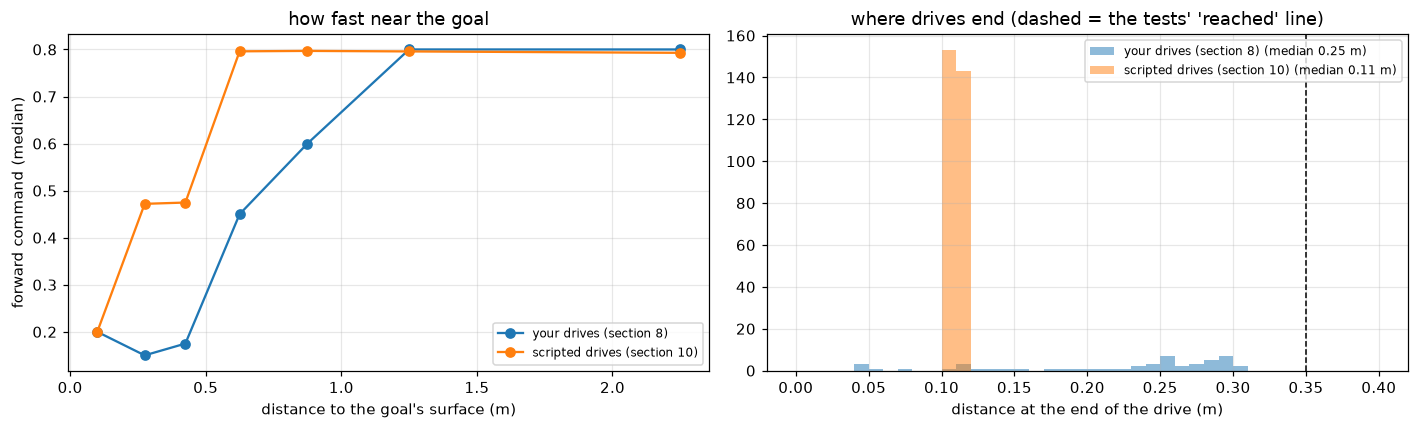

In [13]:
from carsim.recording import load_table
import pandas as pd
def load_many(names):
    return pd.concat([load_table(DATASETS / n) for n in names if (DATASETS / n).exists()], ignore_index=True)
groups = {"your drives (section 8)": ["human_demos"],
          "scripted drives (section 10)": [f"expert_sgc_{k}_{i}" for k in ("rooms", "words") for i in (1, 2, 3)]}
bins = np.array([0, 0.2, 0.35, 0.5, 0.75, 1.0, 1.5, 3.0])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, names in groups.items():
    t = load_many(names)
    if not len(t):
        continue
    t = t.copy(); t["ep"] = t["episode_index"].astype(str) + t["sim.episode_seed"].astype(str)
    d, vx, vis = t["sim.goal_rel.surface_distance"].to_numpy(), t["action.vx"].to_numpy(), t["sim.goal_visible"].astype(bool).to_numpy()
    mid = (bins[:-1] + bins[1:]) / 2
    med = [np.median(vx[(d >= a) & (d < b) & vis]) if ((d >= a) & (d < b) & vis).any() else np.nan for a, b in zip(bins[:-1], bins[1:])]
    ax[0].plot(mid, med, "o-", label=name)
    end = t.groupby("ep")["sim.goal_rel.surface_distance"].last()
    ax[1].hist(end, bins=np.linspace(0, 0.4, 41), alpha=0.5, label=f"{name} (median {end.median():.2f} m)")
ax[0].set_xlabel("distance to the goal's surface (m)"); ax[0].set_ylabel("forward command (median)"); ax[0].legend(fontsize=8)
ax[0].set_title("how fast near the goal")
ax[1].axvline(0.35, ls="--", c="k", lw=1); ax[1].set_xlabel("distance at the end of the drive (m)"); ax[1].legend(fontsize=8)
ax[1].set_title("where drives end (dashed = the tests' 'reached' line)")
plt.tight_layout(); plt.show()

**How to read it.** If the scripted line (left) follows the human one, the model will learn to approach at a
sensible speed and finish close enough. Two differences remain, and both are fine:
* It always searches **left**, whereas a person often turns towards where they remember the goal. Notebook 04
  trains on these drives **without mirroring** (notebook 03 explains why), so the habit stays consistent.
* It makes many small steering corrections (it turns on about 86% of frames; a person on about 45%), because it
  follows a planned route.

## 11. Summary and next step

**What we built**
- ✅ `scripts/record.py`, a recording app with READY → DRIVING → REVIEW phases, keep/discard,
  prompt editing, crash-safe saving, appending sessions and an attempts log.
- ✅ LeRobot v3 datasets with camera video, speed, actions, prompts and privileged `sim.*` ground truth.
- ✅ Checks: a pipeline test with the expert, an image↔action pairing test, and a data-quality dashboard.
- ✅ **The training data:** 300 scripted drives (`runs/datasets/expert_sgc_*`) in ordinary rooms and in scenes where
  only the words tell which object to drive to, with a human-like finish.

**What you learned**
- Behaviour cloning is supervised learning on (observation → action) pairs, and the model copies
  the data's quality.
- *Multimodality* (why we use flow matching) and *compounding errors* (why variety, and later RL, matter).
- How the LeRobot format stores frames, episodes, tasks and videos, and how to read it back.
- A scripted driver is only good training data if everything it does can be explained from the camera picture.

**Next: notebook 03, preparing the data for training.** A train/validation split by room layout, action chunks,
scaling, augmentation, and a fast data loader.